# Import libraries

In [1]:
import torch
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load dataset

In [ ]:
train_set = torchvision.datasets.FashionMNIST("./data", download=True, train=True, transform=transforms.Compose([transforms.ToTensor()]))

In [4]:
batch_size = 32
train_loader = DataLoader(train_set, batch_size=batch_size , shuffle = True)

# Visualize

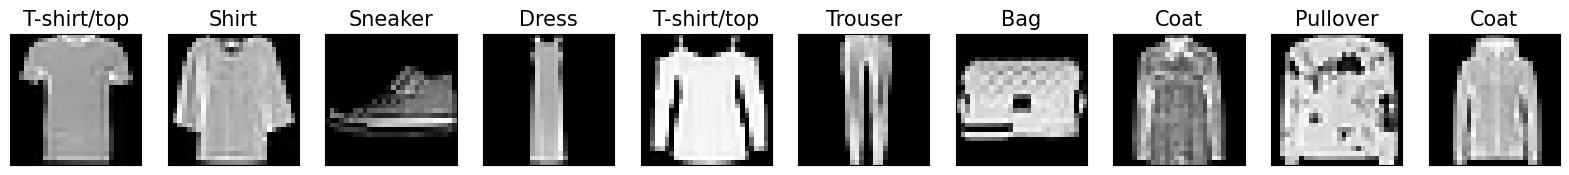

In [5]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

nsamples=10
classes_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal','Shirt', 'Sneaker', 'Bag', 'Ankle boot']
imgs, labels = next(iter(train_loader))

fig=plt.figure(figsize=(20,5),facecolor='w')
for i in range(nsamples):
    ax = plt.subplot(1,nsamples, i+1)
    plt.imshow(imgs[i, 0, :, :], vmin=0, vmax=1.0, cmap=cm.gray)
    ax.set_title("{}".format(classes_names[labels[i]]), fontsize=15)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.savefig('fashionMNIST_samples.png', bbox_inches='tight')
plt.show()

# Model

In [6]:
input_size = 28 * 28
num_classes = 10
epochs = 20
lr = 1e-3

## Discriminator

In [7]:
class Discriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.flat =nn.Flatten()
    self.dis_model=nn.Sequential(
        nn.Linear(784, 1024),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(1024, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )

  def forward(self, x):
    x=self.flat(x)
    out=self.dis_model(x)
    return out

In [8]:
discriminate =Discriminator().to(device)

## Genarator

In [9]:
class Generator(nn.Module):
  def __init__(self):
    super().__init__()
    self.gen_model=nn.Sequential(
        nn.Linear(100, 256),
        nn.ReLU(),
        nn.Linear(256, 512),
        nn.ReLU(),
        nn.Linear(512, 1024),
        nn.ReLU(),
        nn.Linear(1024, 784),
        nn.Tanh()
    )


  def forward(self, x):
    out=self.gen_model(x)
    out=out.view(x.size(0), 1, 28, 28)
    return out

In [10]:
generator =Generator().to(device)

# Train

In [11]:
loss_function =nn.BCELoss()

optim_gen= torch.optim.Adam(generator.parameters(), lr=lr)
optim_dis= torch.optim.Adam(discriminate.parameters(), lr=lr)

In [12]:
for epoch in range(epochs):

  for n, (input_data, labels) in enumerate(train_loader):

    input_data =input_data.to(device)
    input_labels=torch.ones((batch_size,1)).to(device)
    noise = torch.randn((batch_size, 100)).to(device)
    fake_labels=torch.zeros((batch_size,1)).to(device)
    generated_data =  generator(noise)
    all_data = torch.cat((input_data, generated_data))
    all_labels= torch.cat((input_labels, fake_labels))
    discriminate.zero_grad()
    discriminate_output=discriminate(all_data)
    loss_discrminate = loss_function(discriminate_output, all_labels)
    loss_discrminate.backward()
    optim_dis.step()
    noise = torch.randn((batch_size, 100)).to(device)
    generator.zero_grad()
    generated_output =generator(noise)
    dis_gen_output=discriminate(generated_output)
    loss_generate=loss_function(dis_gen_output, input_labels)
    loss_generate.backward()
    optim_gen.step()

    if n== batch_size-1:
      print(f'Epoch: {epoch+1} Loss Dis: {loss_discrminate} / Loss Gen: {loss_generate}')

Epoch: 1 Loss Dis: 0.0006100338068790734 / Loss Gen: 21.430498123168945
Epoch: 2 Loss Dis: 1.1870195865631104 / Loss Gen: 2.293135404586792
Epoch: 3 Loss Dis: 0.5107824802398682 / Loss Gen: 1.053976058959961
Epoch: 4 Loss Dis: 0.4505719542503357 / Loss Gen: 0.9449372887611389
Epoch: 5 Loss Dis: 0.5082382559776306 / Loss Gen: 1.3098466396331787
Epoch: 6 Loss Dis: 0.5190926790237427 / Loss Gen: 1.2577786445617676
Epoch: 7 Loss Dis: 0.4053550958633423 / Loss Gen: 0.951536238193512
Epoch: 8 Loss Dis: 0.516258180141449 / Loss Gen: 1.3177862167358398
Epoch: 9 Loss Dis: 0.5512592792510986 / Loss Gen: 0.9238179922103882
Epoch: 10 Loss Dis: 0.5188477635383606 / Loss Gen: 1.2377686500549316
Epoch: 11 Loss Dis: 0.5357908010482788 / Loss Gen: 0.9363170266151428
Epoch: 12 Loss Dis: 0.46766626834869385 / Loss Gen: 1.0916903018951416
Epoch: 13 Loss Dis: 0.48893818259239197 / Loss Gen: 1.6518398523330688
Epoch: 14 Loss Dis: 0.6288806200027466 / Loss Gen: 1.0465569496154785
Epoch: 15 Loss Dis: 0.593164

# Test

In [13]:
noise= torch.randn((batch_size , 100)).to(device)
generated_data = generator(noise)

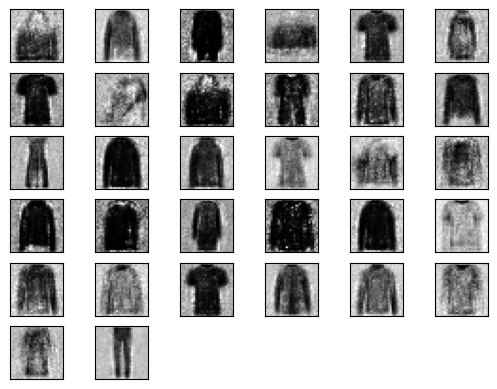

In [14]:
generated_data = generated_data.cpu().detach()

for i in range(32):
    ax = plt.subplot(6, 6, i + 1)
    plt.imshow(generated_data[i].squeeze(), cmap="gray_r")
    plt.xticks([])
    plt.yticks([])